<a href="https://colab.research.google.com/github/IvonneRomero1008/IA-Trabajos-escolares/blob/main/popularidad_spotify.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de popularidad de canciones de Spotify
Por:Ivonne Romero

## Objetivo
Reproducir la práctica de clase usando una red neuronal para estimar
la popularidad de canciones a partir de sus características musicales.

## Procedimiento
Cargo los datos, selecciono las variables, separo entrenamiento y
prueba, estandarizo las entradas, entreno la red y evalúo sus resultados



,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


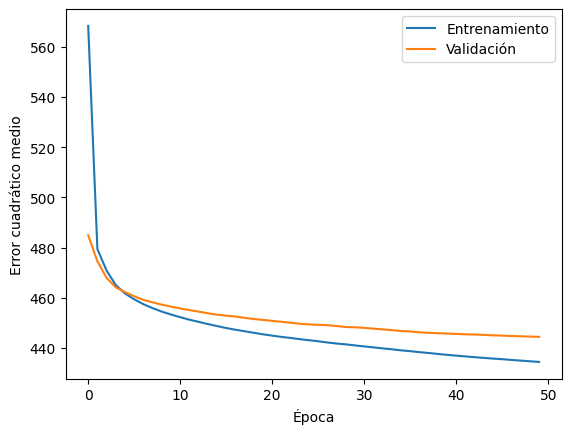

MAE: 16.97
MSE: 439.61
R²: 0.1092


,Popularidad real,Popularidad predicha
0,50,41.209824
1,11,7.748189
2,0,21.938467
3,0,28.726627
4,57,38.171505
5,38,28.297911
6,21,22.950298
7,54,28.304590
8,29,23.548141
9,48,28.665394


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

tf.keras.utils.set_random_seed(42)

# 1. Cargo el dataset proporcionado en clase.
url = "https://raw.githubusercontent.com/mevangelista-alvarado/datasets/refs/heads/main/spotify_songs.csv"
df = pd.read_csv(url)
display(df.head())

# 2. Selecciono las entradas y la popularidad que quiero predecir.
features = [
    "danceability", "energy", "key", "loudness",
    "mode", "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo", "duration_ms"
]

datos = df[features + ["popularity"]].apply(
    pd.to_numeric, errors="coerce"
).replace([np.inf, -np.inf], np.nan).dropna()

X = datos[features].values
y = datos["popularity"].values

# 3. Reservo el 20 % para evaluar el modelo al final.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Estandarizo las entradas usando el entrenamiento como referencia.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Construyo la misma red de la práctica: 64, 32 y 1 neuronas.
model = Sequential([
    Input(shape=(len(features),)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="linear")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# 6. Entreno durante 50 épocas y reservo una parte para validación.
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=50,
    verbose=0
)

# 7. Grafico el error para observar cómo cambió durante el aprendizaje.
plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")
plt.xlabel("Época")
plt.ylabel("Error cuadrático medio")
plt.legend()
plt.show()

# 8. Evalúo con los datos de prueba y comparo las predicciones.
mse, mae = model.evaluate(X_test, y_test, verbose=0)
predicciones = model.predict(X_test, verbose=0).flatten()

print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"R²: {r2_score(y_test, predicciones):.4f}")

display(pd.DataFrame({
    "Popularidad real": y_test,
    "Popularidad predicha": predicciones
}).head(10))

## Conclusión
En esta práctica utilicé una red neuronal para estimar la popularidad de
canciones de Spotify a partir de características como energía, bailabilidad
y ritmo.
El procedimiento incluyó cargar los datos, seleccionar las variables,
separar entrenamiento y prueba, estandarizar las entradas y entrenar el modelo.
Finalmente, el código compara las predicciones con los valores reales y muestra
las métricas MAE, MSE y R².
Para valorar el desempeño del modelo es necesario revisar esas métricas junto
con la gráfica de entrenamiento y validación.
Esta práctica estima la popularidad registrada en el conjunto de datos, no el
éxito futuro de una canción.